<a href="https://colab.research.google.com/github/eduardo-pgoes/sam-pluma-fumaca/blob/main/sam_pluma_fumaca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentação de uma pluma de fumaça com SAM

**Objetivo.** Segmentar a pluma de fumaça da foto abaixo com o *Segment Anything Model* (SAM, ViT-H), avaliar onde a máscara acerta e onde erra, e justificar as melhorias feitas no código, nos prompts e na apresentação da máscara.

**Roteiro**

1. Linha de base sem SAM: regra de cor (fumaça azulada e escura) — serve de referência e, depois, de fonte de prompts.
2. Segmentação automática do SAM (sem prompts) e o que ela erra.
3. Cinco configurações de prompts, cada uma com imagem original, máscara binária e máscara sobreposta lado a lado:
   - C1: só caixa delimitadora;
   - C2: só pontos positivos;
   - C3a: caixa + positivos + negativos mal posicionados;
   - C3b: caixa + positivos + negativos bem posicionados;
   - C4 (melhoria): prompts gerados automaticamente a partir da regra de cor + refinamento iterativo + pós-processamento.
4. Avaliação quantitativa: cobertura da pluma, inclusão de céu, nuvem e edifícios, mapa de incerteza do SAM.
5. Características da imagem que dificultam a segmentação: iluminação, contraste e semelhança fumaça × nuvem, medidas no código.
6. Discussão e máscara final.

> Recomendado: *Ambiente de execução → Alterar o tipo de ambiente → GPU (T4)*. Em CPU o notebook também roda, mas a geração automática de máscaras demora alguns minutos.

## 0. Configuração

In [1]:
import subprocess
import sys
import urllib.request
from pathlib import Path

try:
    import segment_anything
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/facebookresearch/segment-anything.git"], check=True)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from segment_anything import SamAutomaticMaskGenerator, SamPredictor, sam_model_registry

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
REPO_RAW = "https://raw.githubusercontent.com/eduardo-pgoes/sam-pluma-fumaca/main"
IMG_PATH = Path("data/pluma.jpeg")
CKPT = Path("sam_vit_h_4b8939.pth")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

if not IMG_PATH.exists():
    IMG_PATH.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(f"{REPO_RAW}/data/pluma.jpeg", IMG_PATH)
if not CKPT.exists():
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth", CKPT)

plt.rcParams["figure.dpi"] = 80
get_ipython().run_line_magic("config", "InlineBackend.figure_format = 'jpeg'")
print("dispositivo:", DEVICE)

dispositivo: cpu


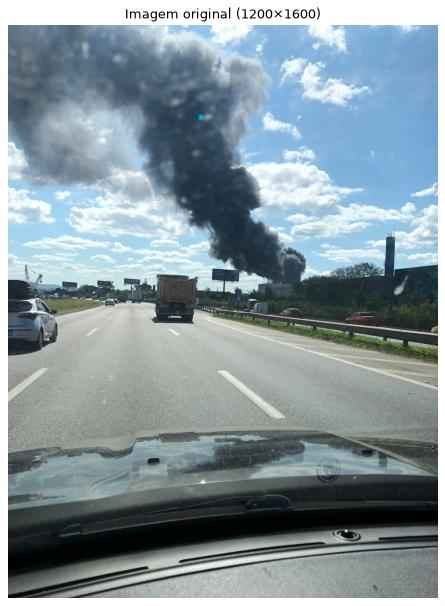

In [2]:
img = cv2.cvtColor(cv2.imread(str(IMG_PATH)), cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]

sam = sam_model_registry["vit_h"](checkpoint=str(CKPT)).to(DEVICE)
predictor = SamPredictor(sam)
predictor.set_image(img)

fig, ax = plt.subplots(figsize=(7, 9.3))
ax.imshow(img)
ax.set_title(f"Imagem original ({W}×{H})")
ax.axis("off")
plt.show()

Foto tirada de dentro de um carro, pelo para-brisa. A pluma sai de trás de um galpão cinza, sobe escura e se abre num "dossel" no canto superior esquerdo, onde fica fina, translúcida e iluminada pelo sol. Ao redor há céu azul, cúmulos brancos, um outdoor, uma torre e árvores. O para-brisa adiciona reflexos, gotas e um *lens flare* (o ponto ciano no meio da pluma).

As figuras mostram só a faixa superior da foto (céu + horizonte, linhas 0–900), onde está a pluma. As máscaras e as métricas são sempre calculadas sobre a imagem inteira.

## 1. Funções de apresentação e de predição

In [3]:
RECORTE = slice(0, 900)


def desenhar_prompts(ax, box=None, pos=(), neg=()):
    if box is not None:
        x0, y0, x1, y1 = box
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="yellow", lw=2.5))
    for x, y in pos:
        ax.scatter(x, y, marker="*", s=320, c="lime", edgecolors="black", linewidths=1.2, zorder=3)
    for x, y in neg:
        ax.scatter(x, y, marker="X", s=200, c="red", edgecolors="white", linewidths=1.2, zorder=3)


def sobrepor(imagem, mask, cor=(255, 40, 40), alpha=0.45):
    out = imagem.copy()
    sel = mask.astype(bool)
    out[sel] = ((1 - alpha) * out[sel] + alpha * np.array(cor)).astype(np.uint8)
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cnts, -1, (255, 255, 0), 3)
    return out


def painel(mask, titulo, box=None, pos=(), neg=()):
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.9))
    axs[0].imshow(img[RECORTE])
    desenhar_prompts(axs[0], box, pos, neg)
    axs[0].set_title("Imagem original + prompts")
    axs[1].imshow(mask[RECORTE], cmap="gray", vmin=0, vmax=1)
    axs[1].set_title("Máscara binária")
    axs[2].imshow(sobrepor(img, mask)[RECORTE])
    axs[2].set_title("Máscara sobreposta")
    for a in axs:
        a.axis("off")
    fig.suptitle(titulo, fontsize=14)
    fig.tight_layout()
    plt.show()


def segmentar(box=None, pos=(), neg=(), multimask=False, mask_input=None, logits=False):
    pts = list(pos) + list(neg)
    m, s, lo = predictor.predict(
        point_coords=np.array(pts, dtype=float) if pts else None,
        point_labels=np.array([1] * len(pos) + [0] * len(neg)) if pts else None,
        box=np.array(box, dtype=float) if box is not None else None,
        mask_input=mask_input,
        multimask_output=multimask,
        return_logits=logits,
    )
    return (m if logits else m.astype(np.uint8)), s, lo


def candidatos(masks, scores, titulo, box=None, pos=(), neg=()):
    fig, axs = plt.subplots(1, len(masks), figsize=(6 * len(masks), 4.9))
    for a, m, s in zip(np.atleast_1d(axs), masks, scores):
        a.imshow(sobrepor(img, m)[RECORTE])
        desenhar_prompts(a, box, pos, neg)
        a.set_title(f"score SAM = {s:.3f}   área = {m.mean():.1%}")
        a.axis("off")
    fig.suptitle(titulo, fontsize=14)
    fig.tight_layout()
    plt.show()

## 2. Linha de base sem SAM: regra de cor

Na foto, a fumaça herda o tom azul do céu (espalhamento atmosférico), mas é bem mais escura que ele; solo, telhados e árvores têm B ≤ R. Regra: pixel azulado (B − R > 25) **e** mais escuro que o céu (V abaixo do limiar de Otsu calculado só sobre os pixels azulados). Depois, abertura/fechamento morfológico e uma abertura larga para cortar a ponte fina entre a base da pluma e o outdoor.

Essa máscara não é verdade de campo. Ela é usada para três coisas: (i) comparar com o SAM, (ii) definir regiões de referência para as métricas e (iii) gerar prompts automaticamente na configuração C4.

limiar de Otsu em V: 167   área da máscara de cor: 13.0%


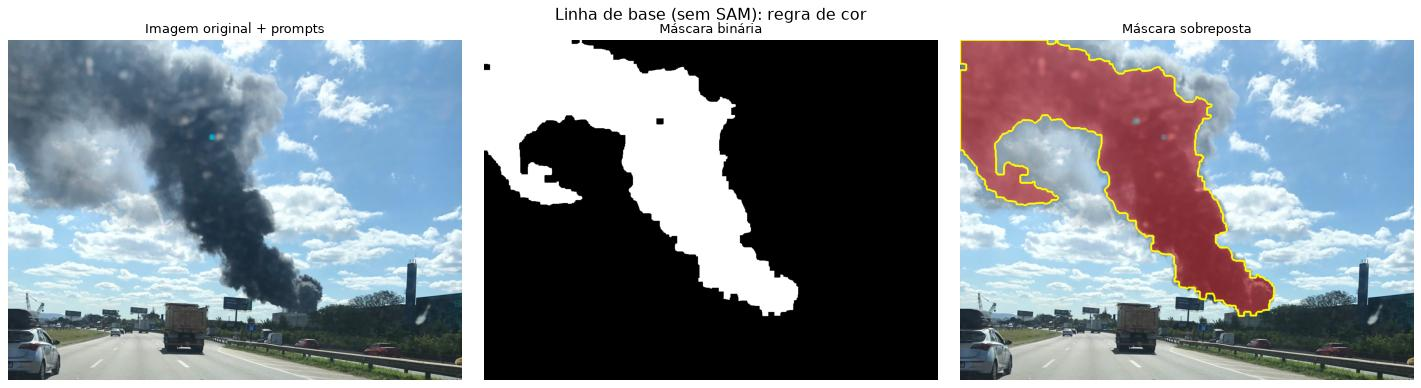

In [4]:
def maior_componente(mask):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    if n < 2:
        return mask.astype(np.uint8)
    return (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)


def prior_cor(rgb, margem_azul=25):
    r = rgb[..., 0].astype(np.int16)
    b = rgb[..., 2].astype(np.int16)
    v = rgb.max(axis=2)
    azul = (b - r) > margem_azul
    limiar, _ = cv2.threshold(v[azul].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = (azul & (v < limiar)).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
    nucleo = maior_componente(cv2.morphologyEx(m, cv2.MORPH_OPEN, k))
    return maior_componente(cv2.dilate(nucleo, k) & m), float(limiar)


prior, LIMIAR_V = prior_cor(img)
print(f"limiar de Otsu em V: {LIMIAR_V:.0f}   área da máscara de cor: {prior.mean():.1%}")
painel(prior, "Linha de base (sem SAM): regra de cor")

**Regiões de referência para as métricas.** Sem máscara anotada à mão, as perguntas "cobre a pluma?", "inclui o que não é pluma?" e "deixa fumaça de fora?" são respondidas com regiões definidas por regras explícitas:

| região | definição | uso |
|---|---|---|
| núcleo da fumaça | máscara de cor erodida 41 px — fumaça com alta confiança | cobertura: quanto do núcleo a máscara pega |
| nuvem branca | V > 225 e S < 45, acima do horizonte, fora do núcleo | inclusão indevida de nuvem |
| céu azul | B − R > 50 e V ≥ limiar de Otsu, fora da máscara de cor | inclusão indevida de céu |
| estruturas | abaixo do horizonte (linha 725) + caixas do outdoor e da torre | inclusão indevida de edifícios/solo |
| vizinhança da pluma | até 100 px da máscara de cor | separa erro grosseiro (longe) de zona de transição (perto) |

Os limiares de nuvem e céu são propositalmente rígidos. Com a regra frouxa usada na máscara de cor (B − R > 25), a fumaça iluminada — clara e ainda azulada — seria contada como "céu" e as métricas acusariam erro onde o SAM acertou. Mesmo assim, fumaça muito fina sobre uma nuvem pode cair na regra de "nuvem branca": "inclusão de nuvem" é uma estimativa, não um erro garantido. A seção 6 mostra onde isso acontece.

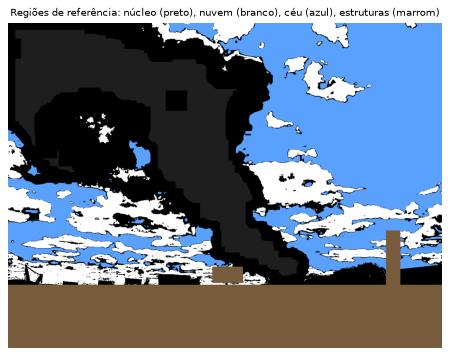

In [5]:
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
V = hsv[..., 2].astype(np.int16)
S = hsv[..., 1].astype(np.int16)
R = img[..., 0].astype(np.int16)
B = img[..., 2].astype(np.int16)
HORIZONTE = 725
OUTDOOR = (565, 675, 650, 720)
TORRE = (1045, 575, 1085, 725)

ceu_area = np.zeros((H, W), bool)
ceu_area[:HORIZONTE] = True
nucleo = cv2.erode(prior, np.ones((41, 41), np.uint8), borderType=cv2.BORDER_CONSTANT, borderValue=0).astype(bool)
nuvem = (V > 225) & (S < 45) & ceu_area & ~nucleo
ceu = ((B - R) > 50) & (V >= LIMIAR_V) & ceu_area & ~prior.astype(bool)
perto = cv2.dilate(prior, np.ones((201, 201), np.uint8)).astype(bool)
estruturas = ~ceu_area
for x0, y0, x1, y1 in (OUTDOOR, TORRE):
    estruturas[y0:y1, x0:x1] = True

ref = np.zeros((H, W, 3), np.uint8)
ref[ceu] = (90, 160, 255)
ref[nuvem] = (255, 255, 255)
ref[estruturas] = (120, 90, 60)
ref[nucleo] = (30, 30, 30)
fig, ax = plt.subplots(figsize=(7, 5.3))
ax.imshow(ref[RECORTE])
ax.set_title("Regiões de referência: núcleo (preto), nuvem (branco), céu (azul), estruturas (marrom)", fontsize=9)
ax.axis("off")
plt.show()

In [6]:
def preencher_buracos(mask):
    m = mask.astype(bool)
    _, lab = cv2.connectedComponents((~m).astype(np.uint8), connectivity=4)
    externos = np.unique(np.r_[lab[0], lab[-1], lab[:, 0], lab[:, -1]])
    return m | (~m & ~np.isin(lab, externos))


def iou(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return (a & b).sum() / max((a | b).sum(), 1)


def avaliar(nome, mask, score=np.nan):
    m = mask.astype(bool)
    area = max(m.sum(), 1)
    n_comp = cv2.connectedComponents(m.astype(np.uint8))[0] - 1
    buracos = (preencher_buracos(m) & ~m).sum()
    return {
        "config": nome,
        "score SAM": score,
        "área (% img)": 100 * m.mean(),
        "cobre núcleo (%)": 100 * (m & nucleo).sum() / nucleo.sum(),
        "fumaça de cor fora (%)": 100 * (prior.astype(bool) & ~m).sum() / prior.sum(),
        "nuvem na máscara (%)": 100 * (m & nuvem).sum() / area,
        "céu na máscara (%)": 100 * (m & ceu).sum() / area,
        "estruturas na máscara (%)": 100 * (m & estruturas).sum() / area,
        "além da cor, perto (%)": 100 * (m & ~prior.astype(bool) & perto).sum() / area,
        "longe da pluma (%)": 100 * (m & ~perto).sum() / area,
        "componentes": n_comp,
        "buracos (px)": int(buracos),
        "IoU c/ regra de cor": iou(m, prior),
    }


resultados = [avaliar("regra de cor (sem SAM)", prior)]
mascaras = {"regra de cor": prior}

## 3. Segmentação automática do SAM (sem prompts)

O `SamAutomaticMaskGenerator` espalha uma grade de 32×32 pontos e devolve todas as máscaras estáveis. Ele não sabe o que é "pluma": segmenta o que tiver borda nítida.

96 máscaras geradas; 6 encostam na pluma; 2 têm mais da metade da área no núcleo da fumaça
melhor máscara isolada: IoU com a regra de cor = 0.79


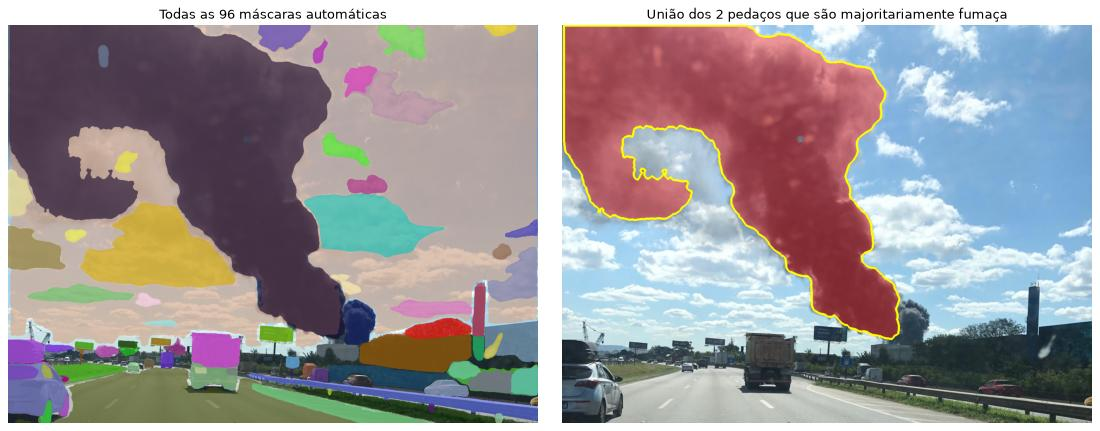

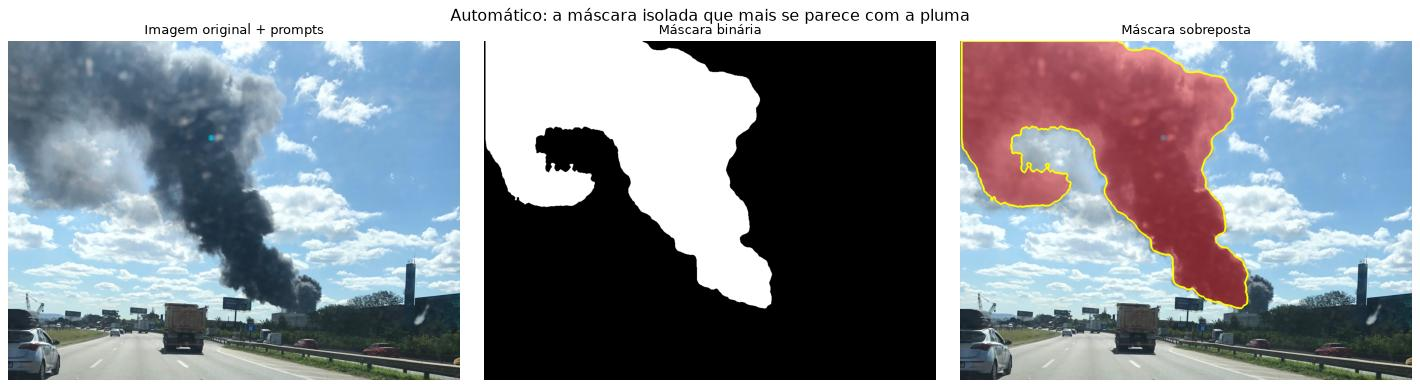

IoU entre a melhor máscara isolada e a união dos pedaços: 1.000


In [7]:
gerador = SamAutomaticMaskGenerator(sam, points_per_side=32, pred_iou_thresh=0.86,
                                    stability_score_thresh=0.92, min_mask_region_area=500)
auto = sorted(gerador.generate(img), key=lambda d: d["area"], reverse=True)

rng = np.random.default_rng(0)
mosaico = img.copy().astype(float)
for d in auto:
    mosaico[d["segmentation"]] = 0.4 * mosaico[d["segmentation"]] + 0.6 * rng.integers(0, 255, 3)

auto_iou = np.array([iou(d["segmentation"], prior) for d in auto])
melhor = auto[int(np.argmax(auto_iou))]["segmentation"].astype(np.uint8)
frac_fumaca = np.array([(d["segmentation"] & nucleo).sum() / d["area"] for d in auto])
toca = np.array([(d["segmentation"] & prior.astype(bool)).any() for d in auto])
pedacos = [d for d, f in zip(auto, frac_fumaca) if f > 0.5]
uniao = np.any([d["segmentation"] for d in pedacos], axis=0).astype(np.uint8) if pedacos else np.zeros((H, W), np.uint8)

print(f"{len(auto)} máscaras geradas; {toca.sum()} encostam na pluma; "
      f"{len(pedacos)} têm mais da metade da área no núcleo da fumaça")
print(f"melhor máscara isolada: IoU com a regra de cor = {auto_iou.max():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 5.3))
axs[0].imshow(mosaico.astype(np.uint8)[RECORTE])
axs[0].set_title(f"Todas as {len(auto)} máscaras automáticas")
axs[1].imshow(sobrepor(img, uniao)[RECORTE])
axs[1].set_title(f"União dos {len(pedacos)} pedaços que são majoritariamente fumaça")
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()

painel(melhor, "Automático: a máscara isolada que mais se parece com a pluma")
print(f"IoU entre a melhor máscara isolada e a união dos pedaços: {iou(melhor, uniao):.3f}")
resultados.append(avaliar("automático (melhor máscara)", melhor))
mascaras["automático"] = melhor

## 4. Configurações de prompts

Coordenadas em pixels da imagem original (x para a direita, y para baixo). Estrelas verdes = pontos positivos, X vermelhos = pontos negativos, retângulo amarelo = caixa.

### C1 — só caixa delimitadora

Com `multimask_output=True` o SAM devolve três hipóteses e um *score* (IoU previsto) para cada uma.

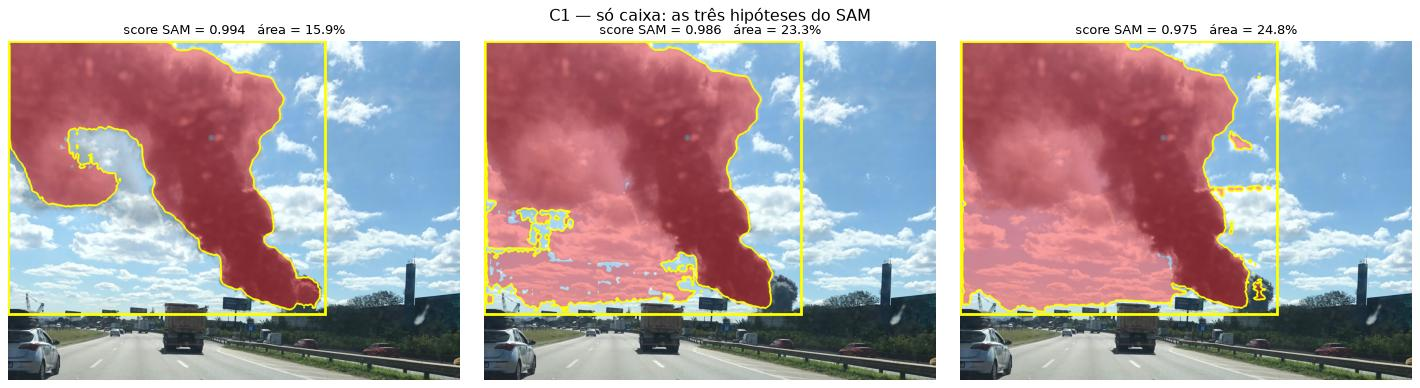

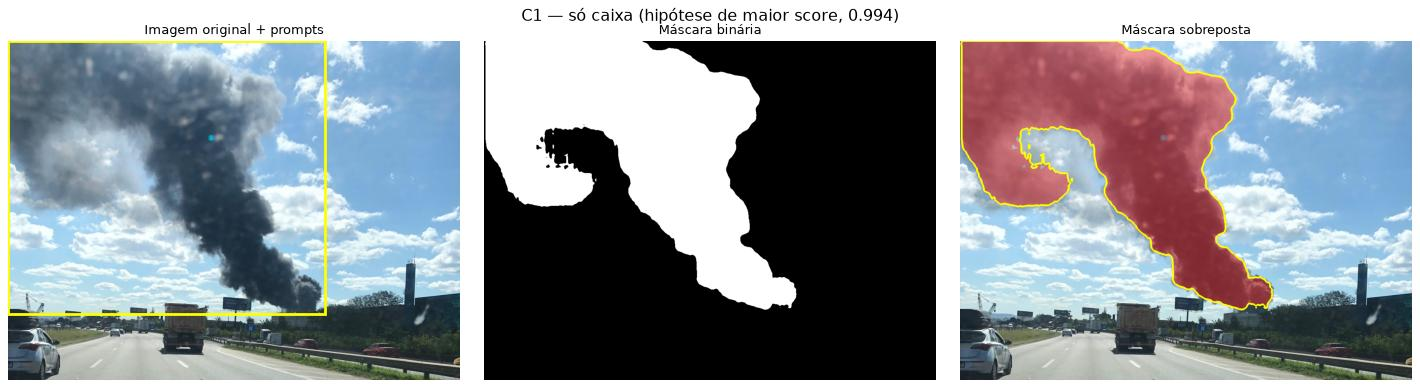

In [8]:
BOX = [0, 0, 840, 725]
m1, s1, _ = segmentar(box=BOX, multimask=True)
candidatos(m1, s1, "C1 — só caixa: as três hipóteses do SAM", box=BOX)
k1 = int(np.argmax(s1))
painel(m1[k1], f"C1 — só caixa (hipótese de maior score, {s1[k1]:.3f})", box=BOX)
resultados.append(avaliar("C1 caixa", m1[k1], s1[k1]))
mascaras["C1"] = m1[k1]

### C2 — só pontos positivos

Cinco pontos ao longo do eixo da pluma, da base ao dossel.

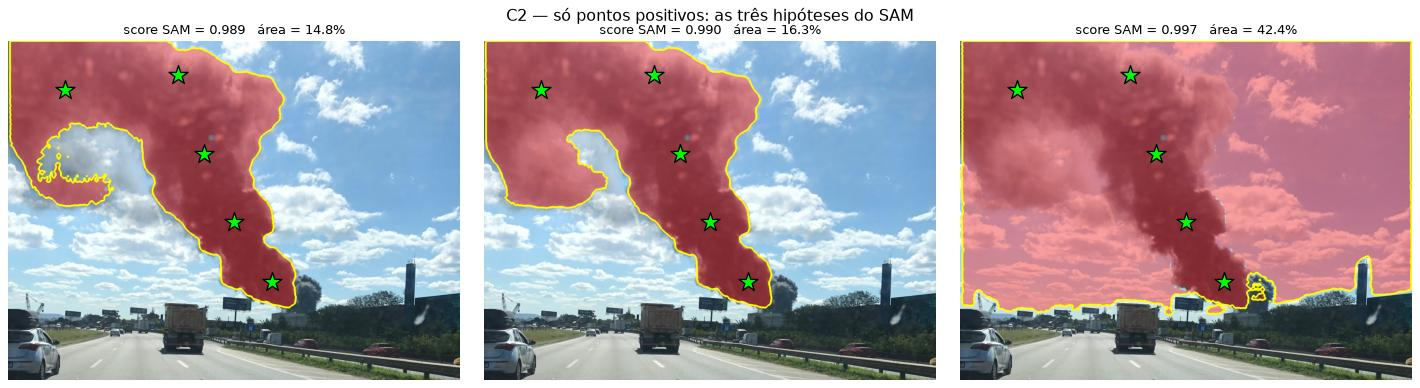

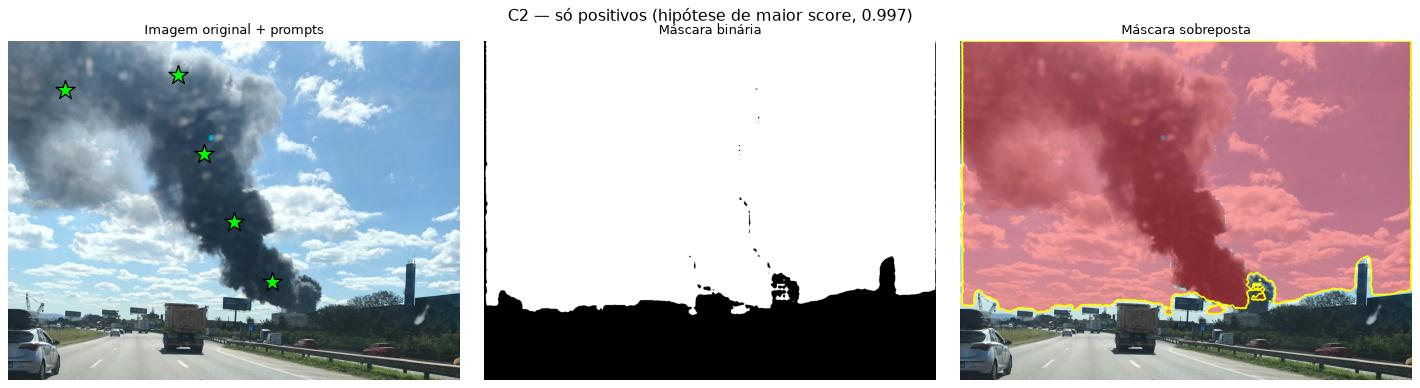

In [9]:
POS = [(700, 640), (600, 480), (520, 300), (450, 90), (150, 130)]
m2, s2, _ = segmentar(pos=POS, multimask=True)
candidatos(m2, s2, "C2 — só pontos positivos: as três hipóteses do SAM", pos=POS)
k2 = int(np.argmax(s2))
painel(m2[k2], f"C2 — só positivos (hipótese de maior score, {s2[k2]:.3f})", pos=POS)
resultados.append(avaliar("C2 positivos", m2[k2], s2[k2]))
mascaras["C2"] = m2[k2]

### C3a — caixa + positivos + negativos mal posicionados

Negativos nas nuvens vizinhas, no céu, no outdoor **e no galpão logo abaixo da base**.

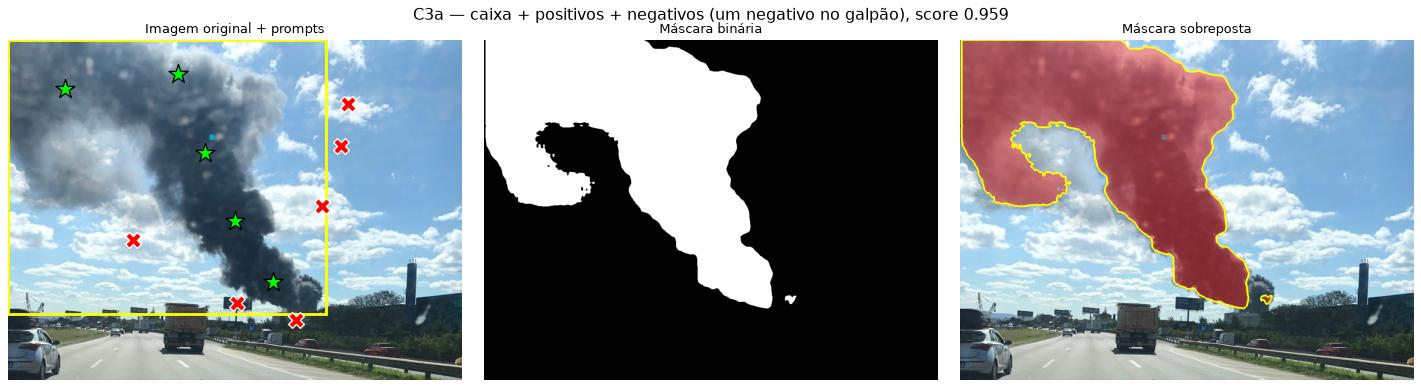

In [10]:
NEG_A = [(830, 440), (330, 530), (880, 280), (605, 697), (760, 740), (900, 170)]
m3a, s3a, _ = segmentar(box=BOX, pos=POS, neg=NEG_A)
painel(m3a[0], f"C3a — caixa + positivos + negativos (um negativo no galpão), score {s3a[0]:.3f}",
       box=BOX, pos=POS, neg=NEG_A)
resultados.append(avaliar("C3a caixa+pos+neg (ruim)", m3a[0], s3a[0]))
mascaras["C3a"] = m3a[0]

### C3b — caixa + positivos + negativos bem posicionados

Correção: tira o negativo do galpão e adiciona um positivo na segunda nuvem de fumaça da base (à direita), que o SAM tratava como objeto separado.

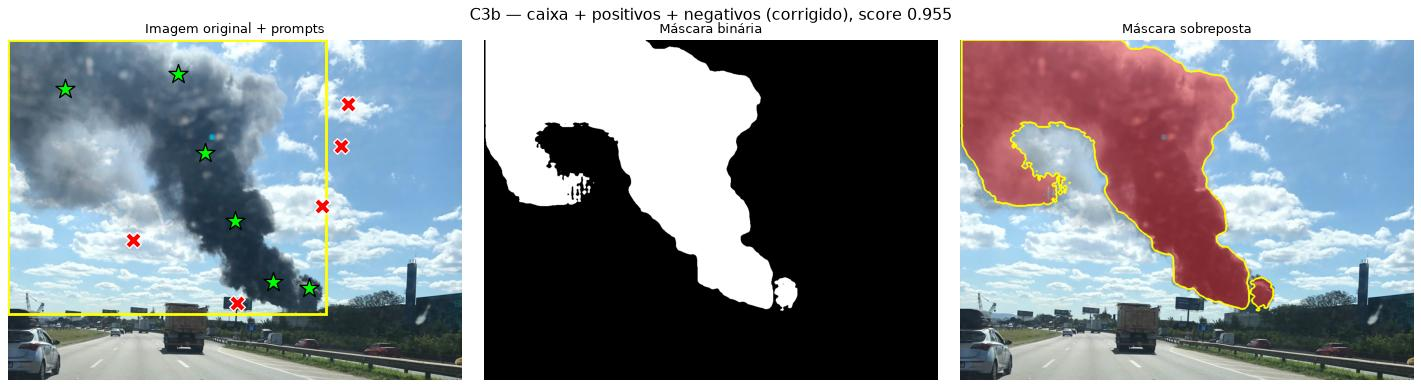

In [11]:
POS_B = POS + [(795, 655)]
NEG_B = [(830, 440), (330, 530), (880, 280), (605, 697), (900, 170)]
m3b, s3b, lo3b = segmentar(box=BOX, pos=POS_B, neg=NEG_B)
painel(m3b[0], f"C3b — caixa + positivos + negativos (corrigido), score {s3b[0]:.3f}",
       box=BOX, pos=POS_B, neg=NEG_B)
resultados.append(avaliar("C3b caixa+pos+neg", m3b[0], s3b[0]))
mascaras["C3b"] = m3b[0]

### C4 — melhoria: prompts automáticos a partir da regra de cor + refinamento + pós-processamento

Em vez de clicar pontos à mão, os prompts saem da linha de base:

- **caixa**: retângulo envolvente da máscara de cor, com 20 px de folga;
- **positivos**: 8 pontos no núcleo da fumaça (máscara de cor erodida 41 px), escolhidos por *farthest point sampling* — espalhados pela pluma inteira, inclusive no dossel;
- **negativos**: 6 pontos de nuvem branca num anel de 20–60 px **em volta** da máscara de cor — exatamente onde a confusão fumaça × nuvem acontece;
- **refinamento**: a saída de baixa resolução (logits 256×256) da 1ª passada volta como `mask_input` numa 2ª passada (o laço de refinamento que o próprio SAM usa no treino);
- **pós-processamento**: mantém só componentes que tocam o núcleo da fumaça e preenche buracos pequenos (< 3000 px), como o *lens flare* do para-brisa, sem fechar o buraco grande do dossel translúcido.

Assim os prompts se ajustam sozinhos se a foto mudar, e o SAM corrige a regra de cor onde ela falha (fumaça iluminada que deixa de ser "escura").

caixa: [0, 0, 851, 751]
positivos: [(609, 481), (20, 20), (186, 412), (455, 102), (796, 694), (218, 168), (415, 339), (20, 266)]
negativos: [(536, 618), (398, 0), (0, 413), (723, 252), (890, 697), (290, 294)]


score 1ª passada 0.949 → 2ª passada 0.984


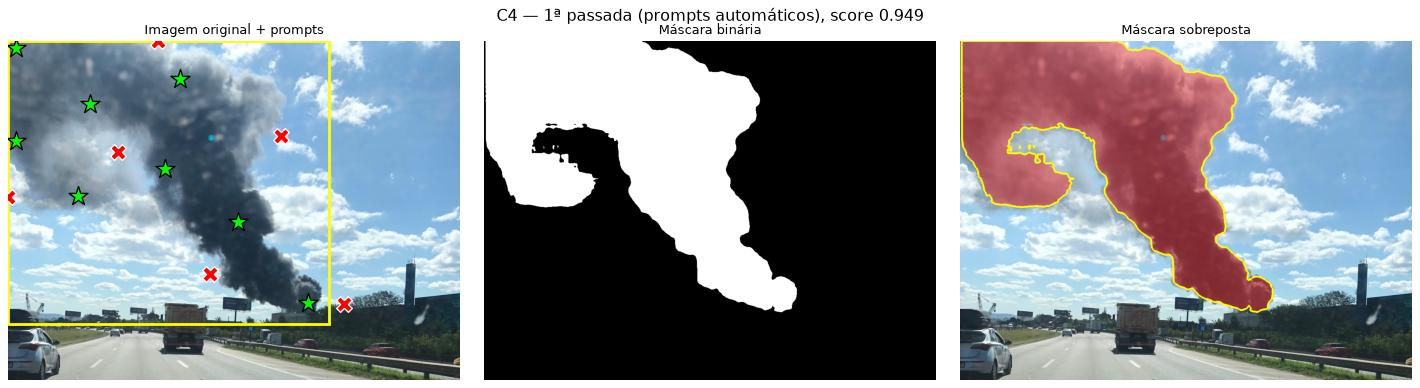

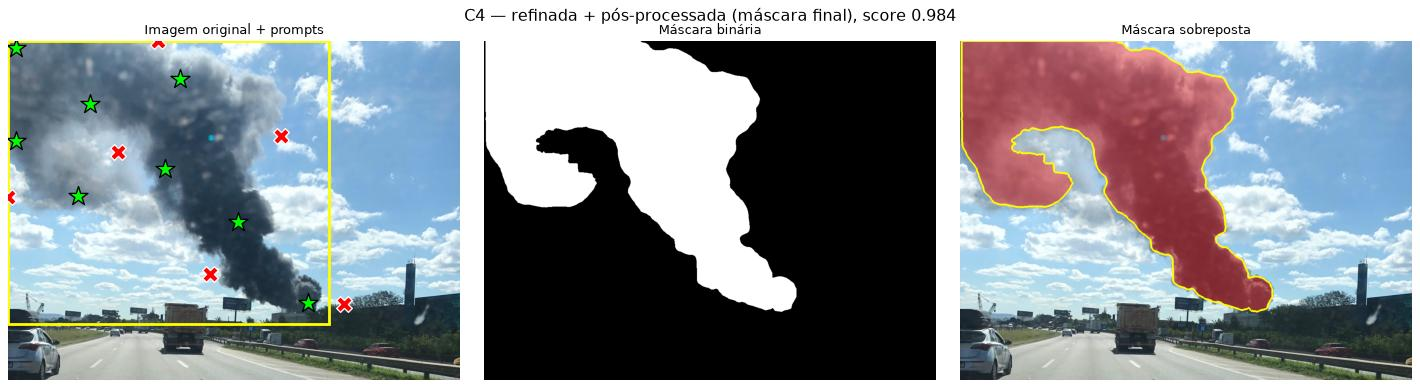

In [12]:
def fps(pontos, n, seed=0):
    rng = np.random.default_rng(seed)
    escolhidos = [pontos[rng.integers(len(pontos))]]
    d = np.full(len(pontos), np.inf)
    for _ in range(n - 1):
        d = np.minimum(d, ((pontos - escolhidos[-1]) ** 2).sum(1))
        escolhidos.append(pontos[np.argmax(d)])
    return [tuple(int(c) for c in p) for p in escolhidos]


def prompts_automaticos(prior, n_pos=8, n_neg=6):
    ys, xs = np.nonzero(nucleo)
    pos = fps(np.c_[xs, ys], n_pos)
    anel = cv2.dilate(prior, np.ones((121, 121), np.uint8)).astype(bool) & \
        ~cv2.dilate(prior, np.ones((41, 41), np.uint8)).astype(bool)
    ys, xs = np.nonzero(anel & nuvem)
    neg = fps(np.c_[xs, ys], n_neg)
    x, y, w, h = cv2.boundingRect(prior)
    box = [max(x - 20, 0), max(y - 20, 0), min(x + w + 20, W), min(y + h + 20, H)]
    return box, pos, neg


def pos_processar(mask, max_buraco=3000):
    n, lab = cv2.connectedComponents(mask.astype(np.uint8))
    manter = [i for i in range(1, n) if (nucleo & (lab == i)).any()]
    m = np.isin(lab, manter)
    buracos = preencher_buracos(m) & ~m
    nb, labb, stats, _ = cv2.connectedComponentsWithStats(buracos.astype(np.uint8))
    pequenos = [i for i in range(1, nb) if stats[i, cv2.CC_STAT_AREA] < max_buraco]
    return (m | np.isin(labb, pequenos)).astype(np.uint8)


BOX4, POS4, NEG4 = prompts_automaticos(prior)
print("caixa:", BOX4)
print("positivos:", POS4)
print("negativos:", NEG4)

m4a, s4a, lo4a = segmentar(box=BOX4, pos=POS4, neg=NEG4)
m4b, s4b, lo4b = segmentar(box=BOX4, pos=POS4, neg=NEG4, mask_input=lo4a)
logits4, _, _ = segmentar(box=BOX4, pos=POS4, neg=NEG4, mask_input=lo4a, logits=True)
final = pos_processar(m4b[0])
print(f"score 1ª passada {s4a[0]:.3f} → 2ª passada {s4b[0]:.3f}")

painel(m4a[0], f"C4 — 1ª passada (prompts automáticos), score {s4a[0]:.3f}", box=BOX4, pos=POS4, neg=NEG4)
painel(final, f"C4 — refinada + pós-processada (máscara final), score {s4b[0]:.3f}", box=BOX4, pos=POS4, neg=NEG4)
resultados.append(avaliar("C4 auto (1ª passada)", m4a[0], s4a[0]))
resultados.append(avaliar("C4 auto + refino + pós", final, s4b[0]))
mascaras["C4"] = final

## 5. Comparação lado a lado e métricas

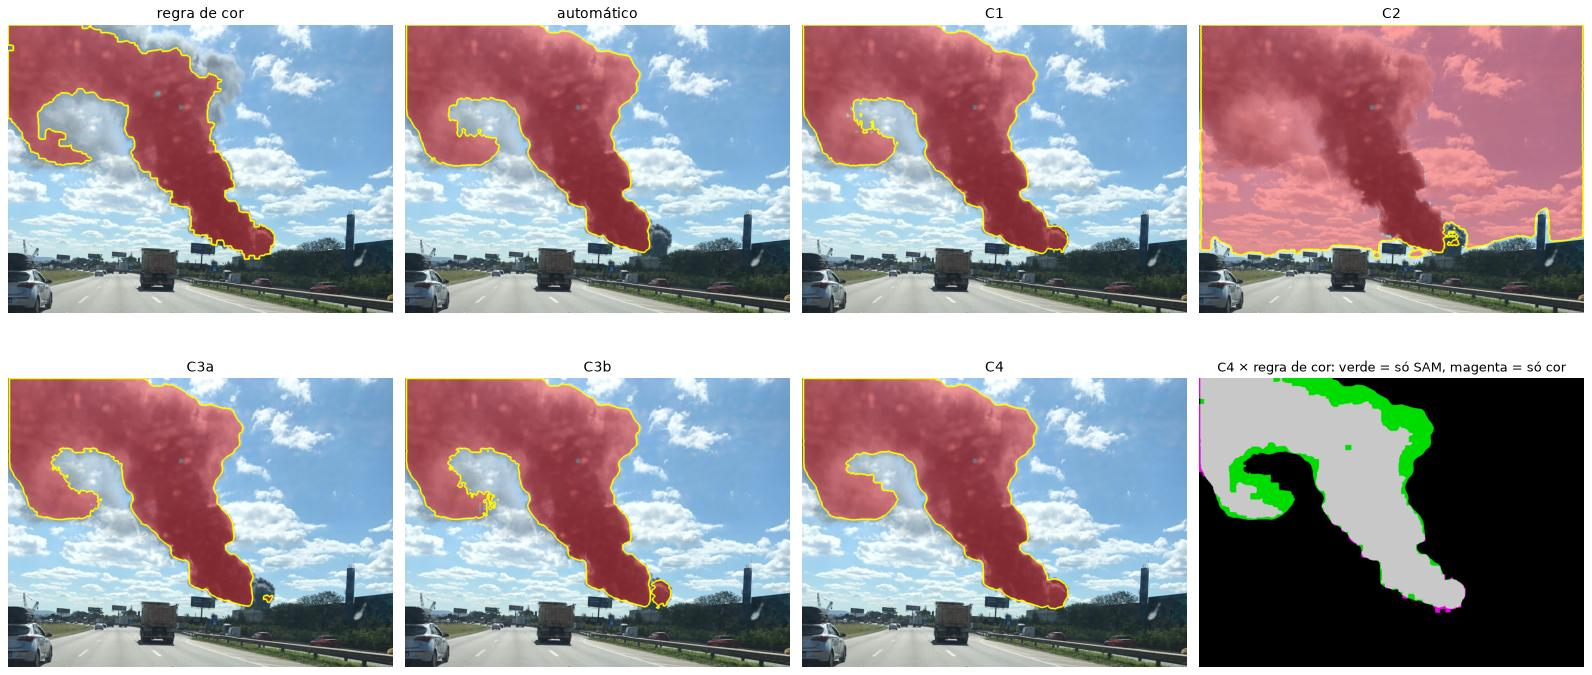

,score SAM,área (% img),cobre núcleo (%),fumaça de cor fora (%),nuvem na máscara (%),céu na máscara (%),estruturas na máscara (%),"além da cor, perto (%)",longe da pluma (%),componentes,buracos (px),IoU c/ regra de cor
config,,,,,,,,,,,,
regra de cor (sem SAM),NaN,12.956,100.000,0.000,0.000,0.000,0.146,0.000,0.000,1,301,1.000
automático (melhor máscara),NaN,15.483,98.908,3.429,1.708,0.429,0.020,19.192,0.000,1,0,0.786
C1 caixa,0.994,15.876,99.986,1.460,1.662,0.398,0.029,19.582,0.000,5,351,0.795
C2 positivos,0.997,42.397,99.300,2.851,17.939,36.590,0.082,31.048,39.265,3,745,0.294
C3a caixa+pos+neg (ruim),0.959,15.420,98.922,3.221,1.734,0.375,0.024,18.682,0.000,5,83,0.792
C3b caixa+pos+neg,0.955,15.491,99.714,1.877,1.737,0.374,0.025,17.932,0.000,7,288,0.808
C4 auto (1ª passada),0.949,15.884,100.000,1.222,1.676,0.401,0.029,19.430,0.000,4,161,0.798
C4 auto + refino + pós,0.984,16.003,100.000,1.133,1.645,0.442,0.027,19.956,0.000,1,0,0.793


In [13]:
ordem = ["regra de cor", "automático", "C1", "C2", "C3a", "C3b", "C4"]
fig, axs = plt.subplots(2, 4, figsize=(20, 9.6))
for a, nome in zip(axs.flat, ordem):
    a.imshow(sobrepor(img, mascaras[nome])[RECORTE])
    a.set_title(nome, fontsize=13)
    a.axis("off")
dif = np.zeros((H, W, 3), np.uint8)
so_sam = final.astype(bool) & ~prior.astype(bool)
so_cor = prior.astype(bool) & ~final.astype(bool)
dif[final.astype(bool) & prior.astype(bool)] = (200, 200, 200)
dif[so_sam] = (0, 220, 0)
dif[so_cor] = (230, 0, 230)
axs.flat[-1].imshow(dif[RECORTE])
axs.flat[-1].set_title("C4 × regra de cor: verde = só SAM, magenta = só cor", fontsize=12)
axs.flat[-1].axis("off")
plt.tight_layout()
plt.show()

tabela = pd.DataFrame(resultados).set_index("config")
tabela.round(3)

In [14]:
nomes = ["C1", "C2", "C3a", "C3b", "C4"]
pares = pd.DataFrame([[iou(mascaras[a], mascaras[b]) for b in nomes] for a in nomes], index=nomes, columns=nomes)
print("IoU entre as configurações:")
pares.round(3)

IoU entre as configurações:


,C1,C2,C3a,C3b,C4
C1,1.000,0.367,0.968,0.971,0.984
C2,0.367,1.000,0.362,0.359,0.369
C3a,0.968,0.362,1.000,0.979,0.960
C3b,0.971,0.359,0.979,1.000,0.964
C4,0.984,0.369,0.960,0.964,1.000


### Onde o SAM está em dúvida

Os logits da máscara final dizem quão longe cada pixel está da fronteira de decisão. Pixels com |logit| < 2 formam a faixa de incerteza: mudar levemente o prompt ou o limiar muda a resposta ali.

dossel translúcido (x<450, y<480)      20158 px  (69.5% da faixa de incerteza)
base / 2ª nuvem (x>700, y>560)          4213 px  (14.5% da faixa de incerteza)
resto da borda                          4644 px  (16.0% da faixa de incerteza)


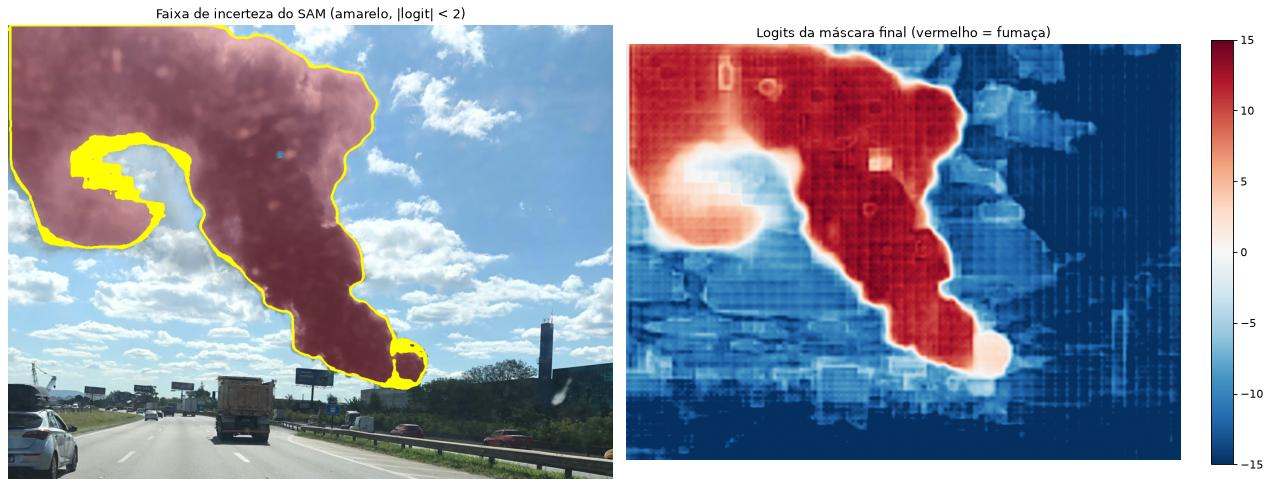

In [15]:
incerto = np.abs(logits4[0]) < 2.0
zonas = {
    "dossel translúcido (x<450, y<480)": incerto[:480, :450].sum(),
    "base / 2ª nuvem (x>700, y>560)": incerto[560:, 700:].sum(),
}
zonas["resto da borda"] = incerto.sum() - sum(zonas.values())
for k, v in zonas.items():
    print(f"{k:36s} {v:7d} px  ({100 * v / incerto.sum():4.1f}% da faixa de incerteza)")

viz = sobrepor(img, final, alpha=0.3)
viz[incerto] = (255, 255, 0)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
axs[0].imshow(viz[RECORTE])
axs[0].set_title("Faixa de incerteza do SAM (amarelo, |logit| < 2)")
im = axs[1].imshow(np.clip(logits4[0], -15, 15)[RECORTE], cmap="RdBu_r", vmin=-15, vmax=15)
axs[1].set_title("Logits da máscara final (vermelho = fumaça)")
plt.colorbar(im, ax=axs[1], fraction=0.035)
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()

## 6. Por que esta imagem é difícil: iluminação, contraste e semelhança fumaça × nuvem

Quatro populações de pixels:

- **fumaça escura**: núcleo da máscara de cor;
- **fumaça iluminada**: dentro da máscara final do SAM mas rejeitada pela regra de cor — a fumaça que o sol clareia;
- **nuvem branca** e **céu azul**: regiões de referência fora da máscara final.

Para cada uma: brilho (V), saturação (S) e azulado (B − R). A sobreposição dos histogramas é medida pelo coeficiente de Bhattacharyya (0 = distribuições disjuntas, 1 = idênticas).

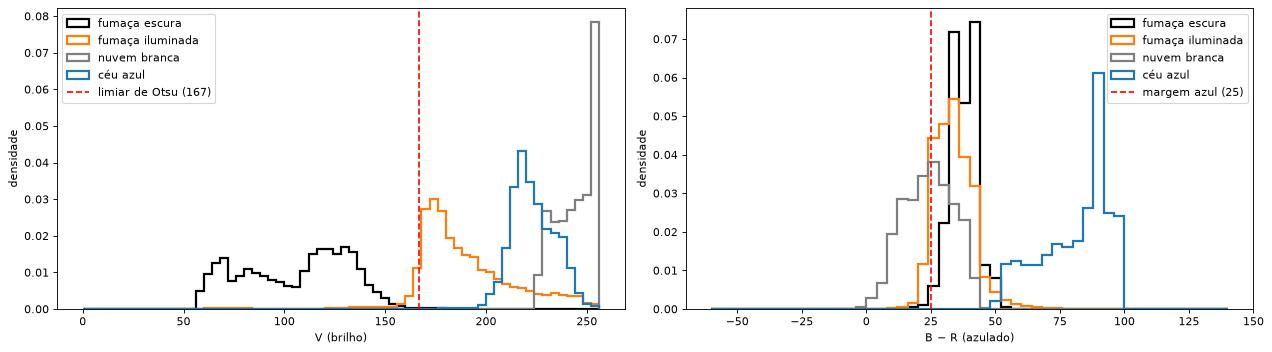

,pixels,V média,V desvio,S média,S desvio,B−R média,B−R desvio
população,,,,,,,
fumaça escura,162796,105.2,26.7,94.6,23.1,37.0,7.1
fumaça iluminada,61314,188.7,24.8,45.8,11.9,33.3,7.5
nuvem branca,151206,244.0,9.4,25.0,10.2,23.5,9.5
céu azul,302840,222.9,10.8,92.8,17.3,80.6,12.9


Sobreposição dos histogramas (Bhattacharyya):


,V,B−R
fumaça escura × nuvem branca,0.006,0.644
fumaça iluminada × nuvem branca,0.295,0.797
fumaça escura × céu azul,0.018,0.053
fumaça iluminada × céu azul,0.541,0.088


In [16]:
f_final = final.astype(bool)
pops = {
    "fumaça escura": nucleo,
    "fumaça iluminada": f_final & ~prior.astype(bool) & ceu_area,
    "nuvem branca": nuvem & ~f_final,
    "céu azul": ceu & ~f_final,
}
canais = {"V": V, "S": S, "B−R": B - R}

linhas = []
for nome, msk in pops.items():
    linha = {"população": nome, "pixels": int(msk.sum())}
    for cn, ch in canais.items():
        linha[f"{cn} média"] = ch[msk].mean()
        linha[f"{cn} desvio"] = ch[msk].std()
    linhas.append(linha)
estat = pd.DataFrame(linhas).set_index("população").round(1)


def bhattacharyya(a, b, bins):
    ha, _ = np.histogram(a, bins=bins)
    hb, _ = np.histogram(b, bins=bins)
    return np.sqrt(ha / ha.sum() * hb / hb.sum()).sum()


bins = {"V": np.arange(0, 257, 4), "B−R": np.arange(-60, 141, 4)}
duplas = [("fumaça escura", "nuvem branca"), ("fumaça iluminada", "nuvem branca"),
          ("fumaça escura", "céu azul"), ("fumaça iluminada", "céu azul")]
sobrep = pd.DataFrame({
    cn: {f"{a} × {b}": bhattacharyya(canais[cn][pops[a]], canais[cn][pops[b]], bins[cn]) for a, b in duplas}
    for cn in bins
}).round(3)

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
cores = {"fumaça escura": "black", "fumaça iluminada": "tab:orange", "nuvem branca": "tab:gray", "céu azul": "tab:blue"}
for nome, msk in pops.items():
    axs[0].hist(V[msk], bins=bins["V"], density=True, histtype="step", lw=2, color=cores[nome], label=nome)
    axs[1].hist((B - R)[msk], bins=bins["B−R"], density=True, histtype="step", lw=2, color=cores[nome], label=nome)
axs[0].axvline(LIMIAR_V, ls="--", c="red", label=f"limiar de Otsu ({LIMIAR_V:.0f})")
axs[0].set_xlabel("V (brilho)")
axs[1].axvline(25, ls="--", c="red", label="margem azul (25)")
axs[1].set_xlabel("B − R (azulado)")
for a in axs:
    a.legend()
    a.set_ylabel("densidade")
plt.tight_layout()
plt.show()
display(estat)
print("Sobreposição dos histogramas (Bhattacharyya):")
display(sobrep)

### Contraste na borda da máscara

Para os trechos de borda da máscara final que encostam em **céu azul** e os que encostam em **nuvem branca**, compara-se o brilho logo dentro (anel de 9 px) com o brilho logo fora, e mede-se o gradiente (Sobel) de V sobre a borda. Borda fraca = o SAM tem pouca informação para decidir onde cortar.

,px de borda,V dentro,V fora,contraste de Michelson,gradiente médio |∇V|
trecho,,,,,
borda com céu azul,1169,194.480,216.676,0.054,755.874023
borda com nuvem branca,631,188.913,241.492,0.122,1481.895996


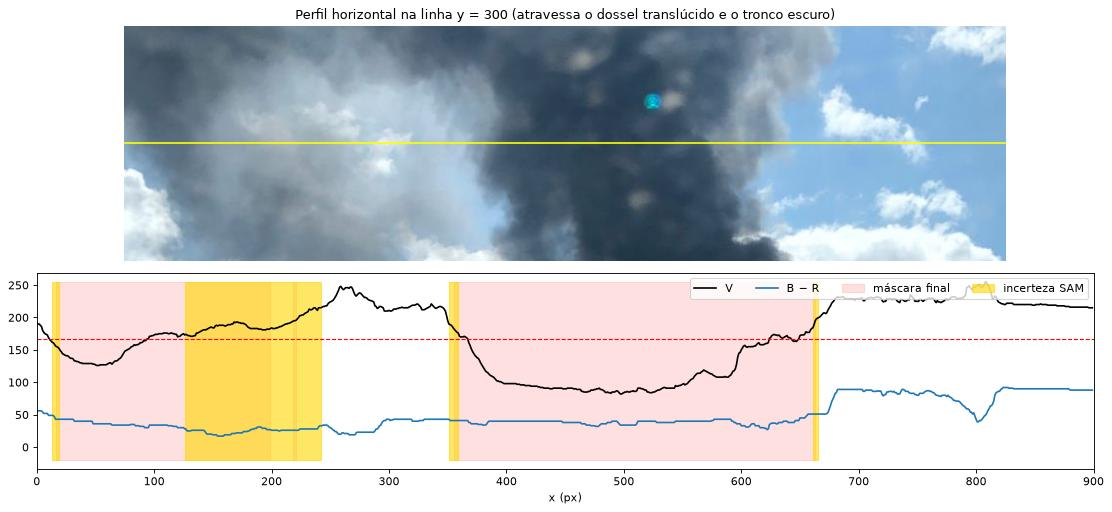

In [17]:
k9 = np.ones((9, 9), np.uint8)
borda = f_final & ~cv2.erode(final, np.ones((3, 3), np.uint8)).astype(bool)
dentro = f_final & ~cv2.erode(final, k9).astype(bool)
fora = cv2.dilate(final, k9).astype(bool) & ~f_final
perto_nuvem = cv2.dilate((fora & nuvem).astype(np.uint8), k9).astype(bool)
perto_ceu = cv2.dilate((fora & ceu).astype(np.uint8), k9).astype(bool) & ~perto_nuvem
gx = cv2.Sobel(V.astype(np.float32), cv2.CV_32F, 1, 0, ksize=5)
gy = cv2.Sobel(V.astype(np.float32), cv2.CV_32F, 0, 1, ksize=5)
grad = np.hypot(gx, gy)

linhas = []
for nome, perto, viz_ref in [("borda com céu azul", perto_ceu, ceu), ("borda com nuvem branca", perto_nuvem, nuvem)]:
    v_in = V[dentro & perto].mean()
    v_out = V[fora & perto & viz_ref].mean()
    linhas.append({
        "trecho": nome,
        "px de borda": int((borda & perto).sum()),
        "V dentro": v_in,
        "V fora": v_out,
        "contraste de Michelson": (v_out - v_in) / (v_out + v_in),
        "gradiente médio |∇V|": grad[borda & perto].mean(),
    })
contraste = pd.DataFrame(linhas).set_index("trecho").round(3)
display(contraste)

Y_PERFIL = 300
fig, axs = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
axs[0].imshow(img[Y_PERFIL - 120:Y_PERFIL + 120, :900], extent=(0, 900, 240, 0))
axs[0].axhline(120, c="yellow", lw=1.5)
axs[0].set_title(f"Perfil horizontal na linha y = {Y_PERFIL} (atravessa o dossel translúcido e o tronco escuro)")
axs[0].axis("off")
xs = np.arange(900)
axs[1].plot(xs, V[Y_PERFIL, :900], c="black", label="V")
axs[1].plot(xs, (B - R)[Y_PERFIL, :900], c="tab:blue", label="B − R")
axs[1].fill_between(xs, -20, 255, where=f_final[Y_PERFIL, :900], color="red", alpha=0.12, label="máscara final")
axs[1].fill_between(xs, -20, 255, where=incerto[Y_PERFIL, :900], color="gold", alpha=0.6, label="incerteza SAM")
axs[1].axhline(LIMIAR_V, ls="--", c="red", lw=1)
axs[1].legend(loc="upper right", ncol=4)
axs[1].set_xlabel("x (px)")
plt.tight_layout()
plt.show()

## 7. Discussão

Os números abaixo são da execução registrada neste notebook (CPU). Em GPU podem variar na terceira casa decimal.

### A máscara cobre a pluma? Inclui o que não é pluma? Deixa fumaça de fora?

| configuração | cobre a pluma? | inclui o que não é pluma? | deixa fumaça de fora? |
|---|---|---|---|
| regra de cor (sem SAM) | só a parte escura | quase nada | **sim**: toda a borda iluminada pelo sol (≈ 19% da pluma, em verde no mapa de diferenças) e um furo no *lens flare* |
| automático (sem prompt) | a maior parte, numa máscara única | pouco (0,4% de céu) | **sim**: a 2ª nuvem de fumaça da base vira outro objeto (3,4% da fumaça de cor fica de fora) |
| C1 — só caixa | sim (99,99% do núcleo) | pouco, mas sai em 5 pedaços (ilhas pequenas na borda) | quase nada |
| C2 — só positivos | sim | **muito**: a hipótese de maior *score* (0,997) é o céu inteiro — 39% da máscara está longe da pluma, 37% é céu azul e 18% nuvem | — |
| C3a — negativos ruins | sim | pouco | **sim**: o negativo no galpão apaga a 2ª nuvem da base (3,2% de fora) |
| C3b — negativos corrigidos | sim (99,7%) | pouco, mas sai em 7 pedaços | pouco (1,9%) |
| **C4 — automático + refino** | **sim (100% do núcleo)** | pouco (0,4% de céu, 1,6% de "nuvem", 0,03% de estruturas), em 1 componente e sem buracos | **o mínimo (1,1%)**: só a franja da base, rente ao galpão |

O "1,6% de nuvem" que sobra em todas as configurações com caixa está quase todo no dossel translúcido, onde há fumaça fina na frente de um cúmulo. Ali o pixel é uma mistura das duas coisas, e não existe resposta binária certa.

### O que os experimentos ensinam sobre os prompts

- **O *score* do SAM não mede se a máscara é a pluma.** Ele estima quão bem definida é a máscara. O céu inteiro é um objeto muito bem definido, então C2 tira 0,997 com a pior máscara do notebook. Escolher a hipótese pelo *score* sem olhar é um erro.
- **A caixa resolve a ambiguidade de escala.** Só com pontos, o SAM não sabe se você quer a pluma, a pluma + céu ou o céu todo. A caixa elimina as hipóteses grandes demais. Nesta foto, C1 sozinho já chega a IoU 0,98 com a máscara final.
- **Um negativo tem alcance grande.** Em C3a, um único negativo no galpão, abaixo da base, apagou a 2ª nuvem de fumaça. Negativos devem ficar onde está a confusão (nuvens encostadas na pluma), nunca colados a uma parte da pluma.
- **Partes desconectadas pedem um positivo próprio.** A 2ª nuvem da base é separada do tronco por um "pescoço" estreito. O SAM só a incluiu quando ganhou um ponto positivo dela (C3b) ou quando os positivos foram amostrados pela pluma inteira (C4).

### Por que C4 é a melhoria, e o que ela não resolve

- **Prompts gerados pelos dados, não por cliques.** A caixa, os 8 positivos e os 6 negativos saem da regra de cor. Os positivos se espalham por toda a pluma (inclusive na 2ª nuvem da base, que entra sem intervenção manual). Os negativos caem, na maioria, nas nuvens encostadas na fumaça. Isso é reprodutível e se reajusta se a foto mudar.
- **Os dois métodos se corrigem.** A regra de cor perde a fumaça iluminada. O SAM recupera essa borda (verde no mapa de diferenças) porque segue a forma, não o brilho. Em troca, a regra de cor dá ao SAM pontos que ele não erraria.
- **O refinamento com `mask_input` sobe o *score* de 0,949 para 0,984** e estabiliza a borda.
- **O pós-processamento entrega uma máscara utilizável**: 1 componente e 0 buracos, contra 4–7 componentes nas outras configurações com caixa. O furo grande do dossel (nuvem atrás de fumaça fina) é preservado de propósito, porque é maior que o limite de 3000 px.
- **Ganho em área é pequeno.** C4 e C1 têm IoU 0,98. Nesta foto, uma boa caixa já faz quase tudo. O ganho de C4 está na robustez (sem cliques, sem negativos mal postos), na cobertura total do núcleo e na limpeza da máscara.
- **Limitação: C4 herda as hipóteses da regra de cor.** Fumaça cinza ou branca, céu nublado ou pôr do sol quebram a regra "azulado e escuro". Os prompts automáticos sairiam errados, e o SAM seguiria esses prompts.

### Quais características da imagem dificultaram a segmentação?

**Iluminação.** O sol clareia a borda e o dossel da pluma. A fumaça iluminada tem V médio 189, contra 105 da fumaça escura, e passa do limiar de Otsu (167). Por isso a regra de cor perde ≈ 19% da pluma. Pelo brilho, essa fumaça se confunde com o céu: sobreposição de Bhattacharyya 0,54 em V. Brilho sozinho não serve.

**Cor e semelhança fumaça × nuvem.** O azulado (B − R) separa bem fumaça de céu (sobreposição 0,05–0,09). Mas separa mal fumaça de nuvem (0,64 a 0,80): as duas são cinza-neutras. A fumaça é só um pouco mais azulada (B − R 33–37 contra 23,5), por causa da luz do céu espalhada dentro dela. A fumaça grossa ainda se distingue da nuvem pelo brilho (sobreposição 0,006 em V). A fumaça fina e iluminada já não se distingue (0,30 em V, 0,80 em B − R), e ainda tem a mesma textura "em couve-flor" dos cúmulos.

**Contraste.** Ao contrário do esperado, a borda mais fraca não é fumaça × nuvem: é fumaça × céu azul (contraste de Michelson 0,054 e gradiente médio 756), metade da borda com nuvem (0,122 e 1482). Onde a fumaça encontra o céu, ela vai ficando fina e some aos poucos, sem uma borda para o SAM seguir. A pior região é a combinação dos dois problemas: fumaça translúcida na frente de um cúmulo, no dossel. Ali estão **70% dos pixels de incerteza** do SAM, e é ali que C1, C3b e C4 mais discordam. O perfil em y = 300 mostra isso: no dossel, V sobe devagar de 130 para 215 e B − R cai para ≈ 25, sem degrau.

**Outros fatores.**
- A foto foi tirada pelo para-brisa: *lens flare*, reflexos e gotas. O *lens flare* abre um furo de 301 px na regra de cor, que o pós-processamento fecha.
- A base da pluma está escondida atrás do galpão, então o limite inferior da máscara é um palpite em qualquer método.
- A 2ª nuvem de fumaça é ligada ao tronco só por um pescoço estreito.
- A neblina perto do horizonte reduz o contraste.

### Limitações e próximos passos

- **Não há máscara anotada à mão.** As métricas são proxies definidas por regras explícitas e servem para comparar configurações, não para dar uma acurácia absoluta. O próximo passo é anotar uma máscara de referência e calcular IoU e Dice de verdade.
- **A fumaça translúcida pede uma máscara contínua, não binária.** Para isso servem técnicas de *alpha matting* ou o próprio logit do SAM como opacidade.
- Vale testar **SAM 2.1** (bordas melhores) e modelos com prompt de texto, como o **SAM 3** com "smoke". Eles dispensariam a regra de cor como fonte de prompts.

## 8. Máscara final

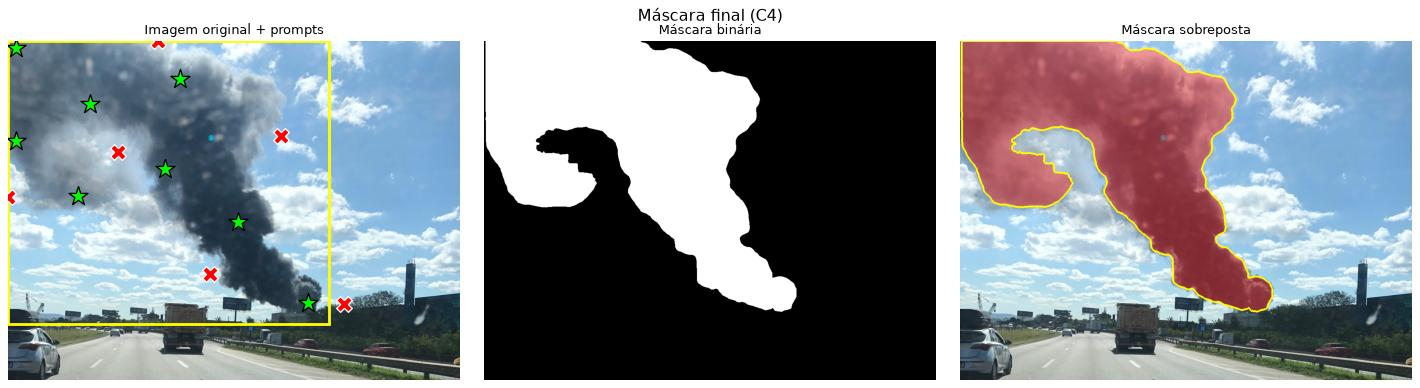

salvo em outputs/mascara_final.png e outputs/sobreposicao_final.png


In [18]:
cv2.imwrite(str(OUT / "mascara_final.png"), final * 255)
cv2.imwrite(str(OUT / "sobreposicao_final.png"), cv2.cvtColor(sobrepor(img, final), cv2.COLOR_RGB2BGR))
painel(final, "Máscara final (C4)", box=BOX4, pos=POS4, neg=NEG4)
print("salvo em", OUT / "mascara_final.png", "e", OUT / "sobreposicao_final.png")